Build a logistic regression model to predict customer churn. Start with exploratory data
analysis to identify important features, encode categorical variables, and then use these features
in logistic regression models.

Deliverables:

● A detailed Jupyter notebook that includes data preprocessing, EDA, model training, and
validation.

● ROC Curve and AUC score to evaluate the model's classification performance.

In [75]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns

In [76]:
customer = pd.read_csv(r"C:\Users\BerniceBoateng\Downloads\archive (6)\WA_Fn-UseC_-Telco-Customer-Churn.csv")
customer.head(3)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


In [77]:
customer.shape

(7043, 21)

In [78]:
customer.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [79]:
customer.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [80]:
customer.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [81]:
customer.duplicated().sum()

0

In [82]:
# dropping duplicates
customer.drop_duplicates(inplace=True)

In [83]:
customer.duplicated().sum()

0

In [84]:
# changing the string columns to lower case
customer.columns = customer.columns.str.lower()

string_columns = customer.select_dtypes(include=['object']).columns
for col in string_columns:
    customer[col] = customer[col].str.lower()

customer.head(3)


,customerid,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,...,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges,churn
0,7590-vhveg,female,0,yes,no,1,no,no phone service,dsl,no,...,no,no,no,no,month-to-month,yes,electronic check,29.85,29.85,no
1,5575-gnvde,male,0,no,no,34,yes,no,dsl,yes,...,yes,no,no,no,one year,no,mailed check,56.95,1889.5,no
2,3668-qpybk,male,0,no,no,2,yes,no,dsl,yes,...,no,no,no,no,month-to-month,yes,mailed check,53.85,108.15,yes


In [85]:
# dropping the customer-id columnbecause its not important in the orediction of customer churn
customer.drop('customerid',axis=1,inplace=True)
customer.head(3)

,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,onlinebackup,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges,churn
0,female,0,yes,no,1,no,no phone service,dsl,no,yes,no,no,no,no,month-to-month,yes,electronic check,29.85,29.85,no
1,male,0,no,no,34,yes,no,dsl,yes,no,yes,no,no,no,one year,no,mailed check,56.95,1889.5,no
2,male,0,no,no,2,yes,no,dsl,yes,yes,no,no,no,no,month-to-month,yes,mailed check,53.85,108.15,yes


#### Exploring the gender column

In [86]:
customer['gender'].unique()

array(['female', 'male'], dtype=object)

In [87]:
customer['gender'].value_counts()

gender
male      3555
female    3488
Name: count, dtype: int64

##### Visualizing gender distribution

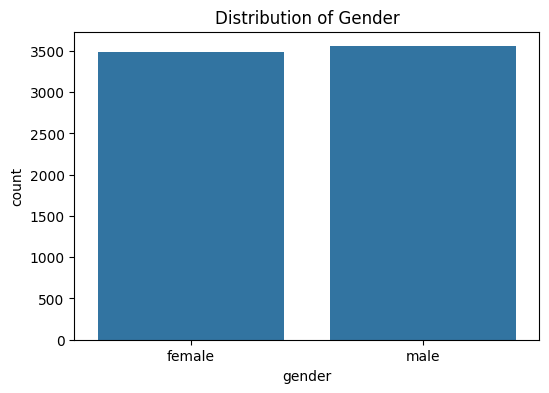

In [88]:
plt.figure(figsize=(6, 4))
sns.countplot(x='gender', data=customer)
plt.title('Distribution of Gender')
plt.show()

##### Relationship between gender and churn

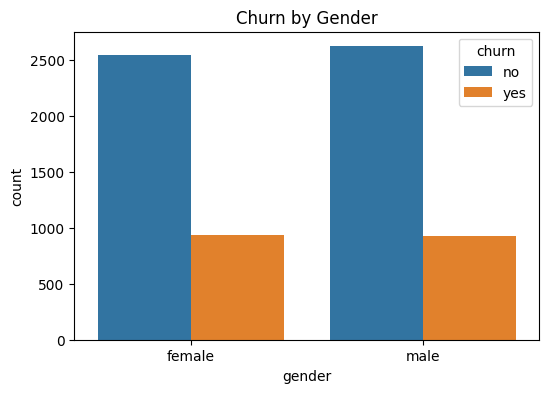

In [89]:
plt.figure(figsize=(6, 4))
sns.countplot(x='gender', hue='churn', data=customer)   
plt.title('Churn by Gender')
plt.show()

##### exact churn percentage by gender

In [90]:
gender_churn_prob = pd.crosstab(customer['gender'], customer['churn'], normalize='index')
print(gender_churn_prob)

churn         no       yes
gender                    
female  0.730791  0.269209
male    0.738397  0.261603


##### encoding gender into 0 for male and 1 for female

In [91]:
customer['gender']=customer['gender'].map({'male':0,'female':1})   
customer.head(3) 

,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,onlinebackup,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges,churn
0,1,0,yes,no,1,no,no phone service,dsl,no,yes,no,no,no,no,month-to-month,yes,electronic check,29.85,29.85,no
1,0,0,no,no,34,yes,no,dsl,yes,no,yes,no,no,no,one year,no,mailed check,56.95,1889.5,no
2,0,0,no,no,2,yes,no,dsl,yes,yes,no,no,no,no,month-to-month,yes,mailed check,53.85,108.15,yes


In [92]:
customer['gender'].unique()

array([1, 0], dtype=int64)

#### Exploring the senior column

In [93]:
customer['seniorcitizen'].unique()

array([0, 1], dtype=int64)

In [94]:
customer['seniorcitizen'].value_counts()

seniorcitizen
0    5901
1    1142
Name: count, dtype: int64

##### Relationship between senior citizen and churn

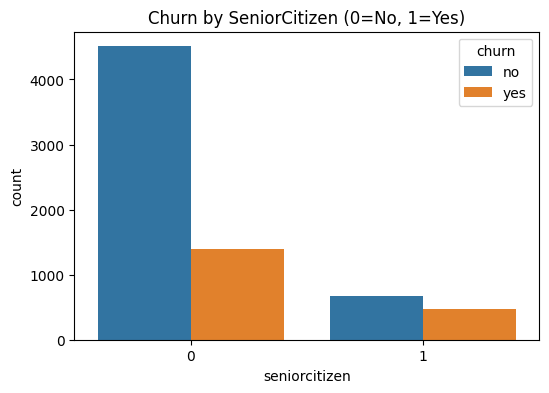

churn                no       yes
seniorcitizen                    
0              0.763938  0.236062
1              0.583187  0.416813


In [95]:
# seniorcitizen Analysis
plt.figure(figsize=(6, 4))
sns.countplot(x='seniorcitizen', hue='churn', data=customer)
plt.title('Churn by SeniorCitizen (0=No, 1=Yes)')
plt.show()

# Exact rates
print(pd.crosstab(customer['seniorcitizen'], customer['churn'], normalize='index'))

#### Exploring the partner analysis column

In [96]:
customer['partner'].unique()

array(['yes', 'no'], dtype=object)

In [97]:
customer['partner'].value_counts()

partner
no     3641
yes    3402
Name: count, dtype: int64

##### Relationship between partner and churn

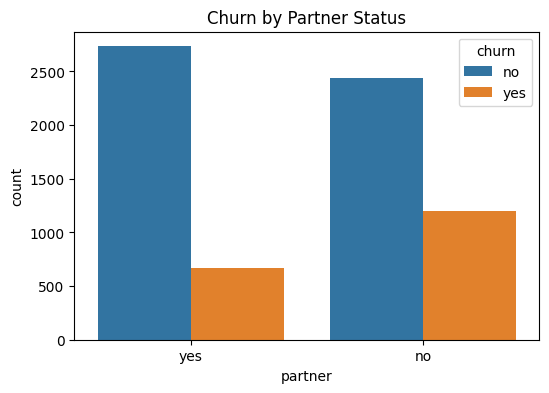


Churn Rate by Partner:
churn          no       yes
partner                    
no       0.670420  0.329580
yes      0.803351  0.196649


In [98]:
# partner analysis
plt.figure(figsize=(6, 4))
sns.countplot(x='partner', hue='churn', data=customer)
plt.title('Churn by Partner Status')
plt.show()
#Exact Churn Rate
print("\nChurn Rate by Partner:")
print(pd.crosstab(customer['partner'], customer['churn'], normalize='index'))


In [99]:
# encoding the partner column...yes --> 1 and no --> 0
customer['partner'] = customer['partner'].map({'yes': 1, 'no': 0})
customer.head(3)

,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,onlinebackup,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges,churn
0,1,0,1,no,1,no,no phone service,dsl,no,yes,no,no,no,no,month-to-month,yes,electronic check,29.85,29.85,no
1,0,0,0,no,34,yes,no,dsl,yes,no,yes,no,no,no,one year,no,mailed check,56.95,1889.5,no
2,0,0,0,no,2,yes,no,dsl,yes,yes,no,no,no,no,month-to-month,yes,mailed check,53.85,108.15,yes


#### Exploring the dependents column

In [ ]:
customer['dependents'].unique()

array(['no', 'yes'], dtype=object)

In [101]:
customer['dependents'].value_counts()

dependents
no     4933
yes    2110
Name: count, dtype: int64

##### Relationship between dependents and churn

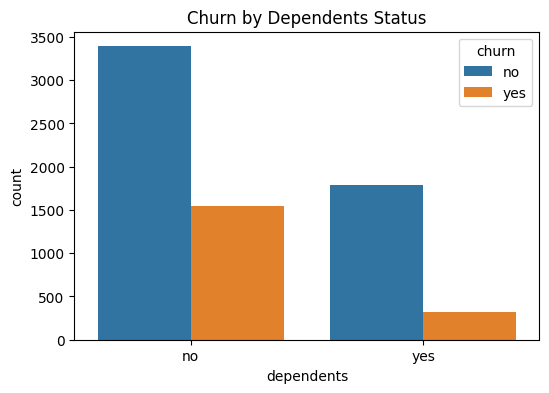


Churn Rate by Dependents:
churn             no       yes
dependents                    
no          0.687209  0.312791
yes         0.845498  0.154502


In [102]:
# analysing dependent column
plt.figure(figsize=(6, 4))
sns.countplot(x='dependents', hue='churn', data=customer)
plt.title('Churn by Dependents Status')
plt.show()

print("\nChurn Rate by Dependents:")
print(pd.crosstab(customer['dependents'], customer['churn'], normalize='index'))

In [103]:
# encoding the dependents column...yes --> 1 and no --> 0
customer['dependents'] = customer['dependents'].map({'yes': 1, 'no': 0})
customer.head(3)

,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,onlinebackup,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges,churn
0,1,0,1,0,1,no,no phone service,dsl,no,yes,no,no,no,no,month-to-month,yes,electronic check,29.85,29.85,no
1,0,0,0,0,34,yes,no,dsl,yes,no,yes,no,no,no,one year,no,mailed check,56.95,1889.5,no
2,0,0,0,0,2,yes,no,dsl,yes,yes,no,no,no,no,month-to-month,yes,mailed check,53.85,108.15,yes


#### exploring the tenure column

In [105]:
customer['tenure'].value_counts()

tenure
1     613
72    362
2     238
3     200
4     176
     ... 
28     57
39     56
44     51
36     50
0      11
Name: count, Length: 73, dtype: int64

In [106]:
customer['tenure'].nunique()

73

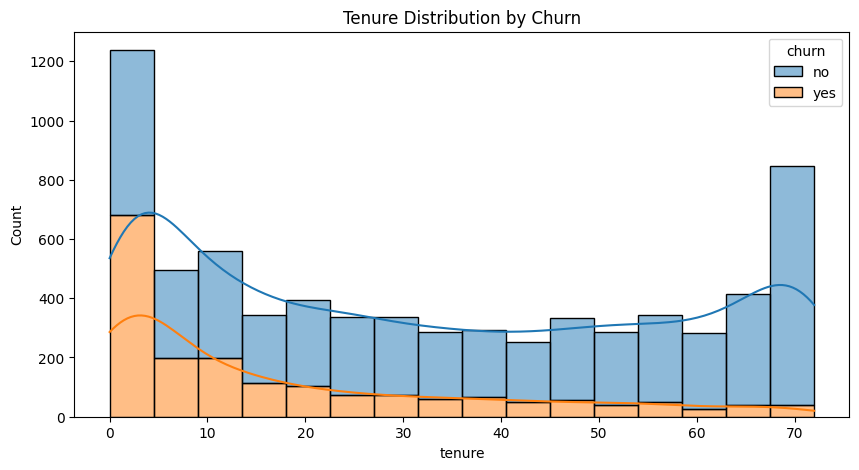

In [107]:
# visualization Histogram overlaid with Churn
plt.figure(figsize=(10, 5))
sns.histplot(x='tenure', hue='churn', data=customer, multiple='stack', kde=True)
plt.title('Tenure Distribution by Churn')
plt.show()

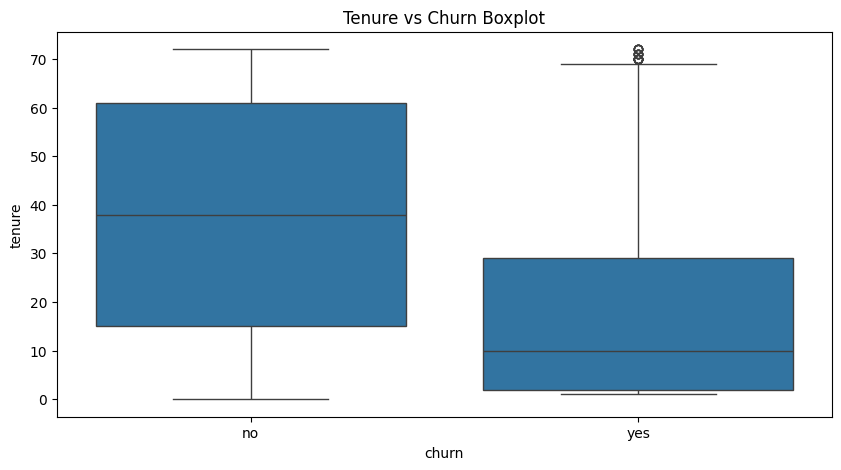


Tenure Statistics:
        count       mean        std  min   25%   50%   75%   max
churn                                                           
no     5174.0  37.569965  24.113777  0.0  15.0  38.0  61.0  72.0
yes    1869.0  17.979133  19.531123  1.0   2.0  10.0  29.0  72.0


In [108]:
# creating a boxplot to  check for outliers
plt.figure(figsize=(10, 5))
sns.boxplot(x='churn', y='tenure', data=customer)
plt.title('Tenure vs Churn Boxplot')
plt.show()
# 3. Basic Statistics
print("\nTenure Statistics:")
print(customer.groupby('churn')['tenure'].describe())

from the result it shows that new cuatomers (customers with low tenure) have a much higher churn rate